In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_excel("Online Retail.xlsx")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print("First 5 Records:")
display(df.head())

print("Dataset Shape:")
print(df.shape)

print("Column Names:")
print(df.columns)

print("Dataset Information:")
df.info()

First 5 Records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Dataset Shape:
(541909, 8)
Column Names:
Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')
Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [4]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Records:
5268


In [5]:
df = df.dropna(subset=['CustomerID'])

df = df.drop_duplicates()

df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

print("Data Cleaning Completed!")
print("Cleaned Dataset Shape:", df.shape)
print("Missing CustomerID:", df['CustomerID'].isnull().sum())
print("Duplicate Records:", df.duplicated().sum())

Data Cleaning Completed!
Cleaned Dataset Shape: (392692, 8)
Missing CustomerID: 0
Duplicate Records: 0


In [6]:
df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

print("Total Purchase Amount Added!")
display(df[['CustomerID', 'Quantity', 'UnitPrice', 'TotalAmount']].head())

Total Purchase Amount Added!


,CustomerID,Quantity,UnitPrice,TotalAmount
0,17850.0,6,2.55,15.30
1,17850.0,6,3.39,20.34
2,17850.0,8,2.75,22.00
3,17850.0,6,3.39,20.34
4,17850.0,6,3.39,20.34


In [7]:
snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalAmount': 'sum'
})

rfm.columns = ['Recency', 'Frequency', 'Monetary']

display(rfm.head())
print("Total Customers:", len(rfm))

C:\Users\Hude Sakshi Mahadev\AppData\Local\Temp\ipykernel_2472\4097815731.py:1: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


Total Customers: 4338


In [8]:
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm)

rfm_scaled = pd.DataFrame(
    rfm_scaled,
    index=rfm.index,
    columns=rfm.columns
)

display(rfm_scaled.head())

print("RFM Features Standardized Successfully!")

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,2.334574,-0.425097,8.363010
12347.0,-0.905340,0.354417,0.251699
12348.0,-0.175360,-0.035340,-0.027988
12349.0,-0.735345,-0.425097,-0.032406
12350.0,2.174578,-0.425097,-0.190812


RFM Features Standardized Successfully!


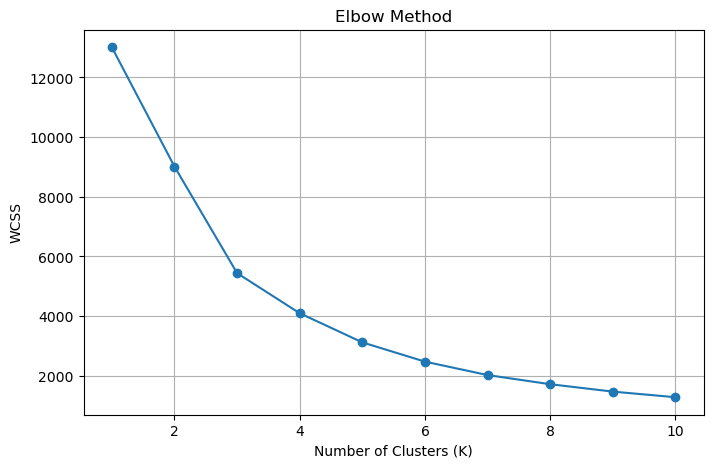

In [9]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.grid()
plt.show()

In [10]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

print("K-Means Clustering Completed!")
print(rfm['Cluster'].value_counts().sort_index())


K-Means Clustering Completed!
Cluster
0    1082
1    3230
2      26
Name: count, dtype: int64


In [11]:
cluster_profile = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean'
}).round(2)

display(cluster_profile)

,Recency,Frequency,Monetary
Cluster,,,
0,247.11,1.58,629.66
1,41.45,4.67,1849.67
2,6.04,66.42,85826.08


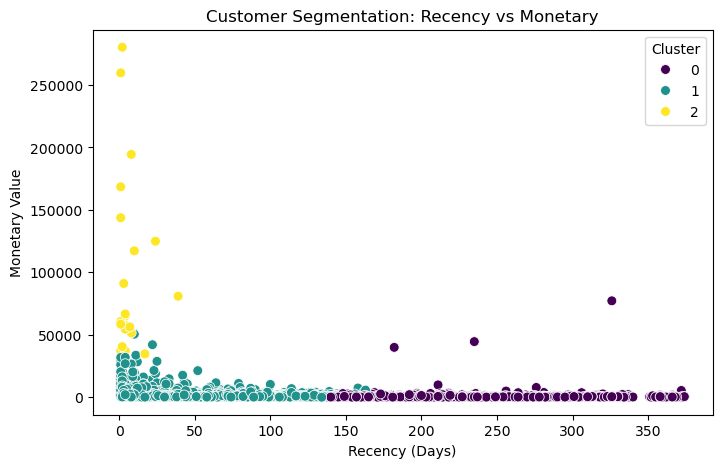

In [12]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Monetary',
    hue='Cluster',
    palette='viridis',
    s=50
)

plt.title('Customer Segmentation: Recency vs Monetary')
plt.xlabel('Recency (Days)')
plt.ylabel('Monetary Value')
plt.show()

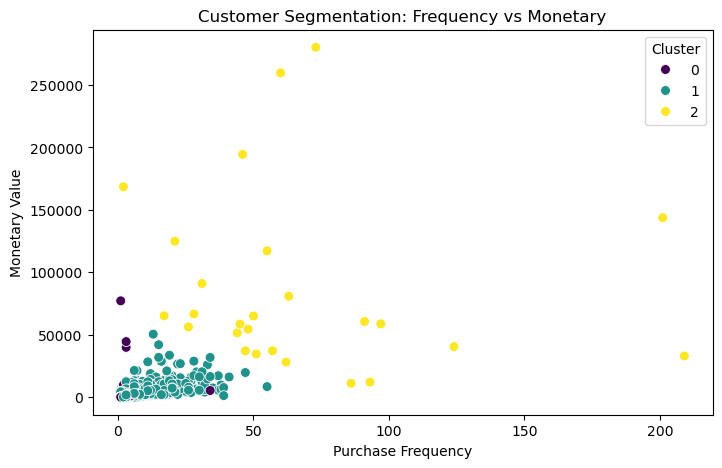

In [13]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Cluster',
    palette='viridis',
    s=50
)

plt.title('Customer Segmentation: Frequency vs Monetary')
plt.xlabel('Purchase Frequency')
plt.ylabel('Monetary Value')
plt.show()

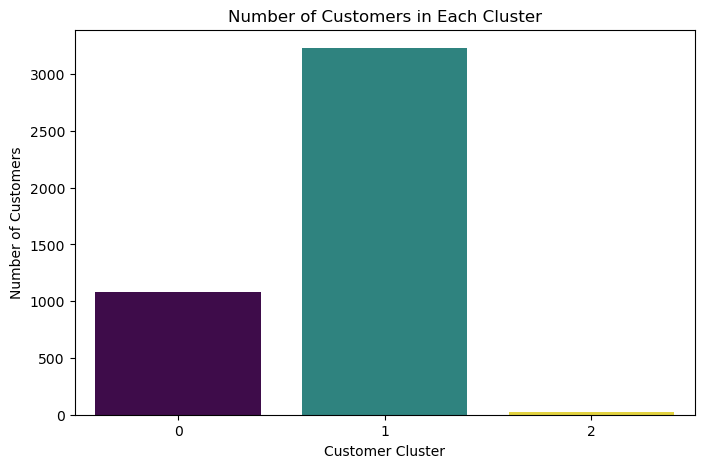

In [14]:
plt.figure(figsize=(8, 5))

sns.countplot(data=rfm, x='Cluster', hue='Cluster', palette='viridis', legend=False)

plt.title('Number of Customers in Each Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')
plt.show()

## Customer Segmentation – Business Insights

### Key Findings
1. **Cluster 0 – At-Risk Customers:** These customers have not purchased for a long time and have low purchase frequency.
2. **Cluster 1 – Regular Customers:** These customers purchase regularly and generate moderate revenue.
3. **Cluster 2 – VIP Customers:** These customers purchase frequently and generate very high revenue.

### Marketing Recommendations
1. Offer special discounts and win-back campaigns to At-Risk Customers.
2. Provide loyalty points and personalized offers to Regular Customers.
3. Give exclusive rewards and premium services to VIP Customers.

### Conclusion
K-Means clustering successfully divided 4,338 customers into three meaningful segments using RFM analysis. This segmentation helps businesses understand customer purchasing behavior and create targeted marketing strategies.